# Thermal adjustment — re-heats and cool-backs of a hot stack (all 39 days)

**Thermal adjustment** (stage added 2026-10-14, `../01_docs/operational-modes.md` §1) is a hot stack with no load whose
temperature is being changed on purpose or after a load stop. Hot standby is a constant temperature only, Start-up
only follows a Shut-down and Part load only follows Hot standby, so every no-load rise or fall of a hot stack that
is not the start of a cool-down belongs here.

| Item | Rule (`operating_states.thermal_adjustment()`) |
|---|---|
| Stack temperature | T > 450 °C (`T_HOT`) |
| Load | I < 1 A per string (`I_LOAD`) |
| Temperature change | \|dT/dt\| ≥ 5 °C/h (`DTDT_STABLE`) |
| History | the stack has been hot before (Hot standby or load) |
| Operations, rise (`REHEAT_OPS`) | *Re-heat (no load)*, *Re-heat to operating temperature* (from the ~510 °C low-temperature hold), *Re-heat to hold* |
| Operations, fall (`COOL_BACK_OPS`) | *Cool-back (no load)*, *Temperature dip during hold* |
| Allowed before | Hot standby, Part load, Rated power |
| Allowed after | Hot standby, Shut-down |
| Not Thermal adjustment | a cool-back that runs straight into a cool-down (that is the Shut-down); the load ramp-down before it (stays Part load) |
| Before load | never straight to Part load: the last 15 min before the first load minute are Hot standby *Pre-load (ready for load)* |

Episodes are split into three kinds by their operations:

| Kind | Test |
|---|---|
| **Re-heat** | only re-heat operations |
| **Cool-back** | only cool-back operations |
| **Mixed** | both (a fall followed by a rise, or the reverse) |

This notebook covers:

1. **Inventory** of the episodes: date, stage before and after, kind, ΔT, duration, rate, whether load follows.
2. **What the hours contain** and the stage arrows in and out.
3. **Rate**, against the 120 °C/h limit, and the 2026-03-13 logger-dropout artefact.
4. **Heater (EAPH) and air** during re-heat and cool-back.
5. **Thermocouple spread** and the inlet-side lead.
6. **What precedes load**: the Pre-load block and the switch from forming gas to natural gas.
7. **Timings**: durations and clock times.
8. **Signal levels** per operation (input for synthetic data).

**Data:** stage and operation labels and episodes come from `04_synthetic_data/library/`
(`traces_1min.parquet`, `episodes.csv`), built by `operating_states.py`. The extra signals are read from
`02_data/downsampled/*_10s.parquet` by `stage_signals.py` and averaged to 1 min; logger-dropout minutes are
blanked there. The re-heat part replaces section 8 of the old start-up notebook and the cool-back part section 8 of
the old shut-down notebook. Tables and figures are saved to `thermal_adjustment/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "scripts")  # helper modules live in 03_data_analysis/scripts/
import operating_states as ops
import stage_signals as ss

pd.set_option("display.max_rows", 120)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)

OUT = Path("thermal_adjustment")
OUT.mkdir(exist_ok=True)
# °C/h, heat-up / cool-down limit (Elcogen p.18, p.20–21; operational-modes.md §4.5)
LIMIT = 120.0
STAGE = ops.ADJUST
KIND_COLORS = {"Re-heat": "#1baf7a", "Cool-back": "#2a78d6", "Mixed": "#eb6834"}
LOAD = ("Part load", "Rated power")
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "lines.linewidth": 1.4,
        "font.size": 9,
    }
)

## 1. Load labels, signals and episodes

`stage_signals.load()` joins the library labels with flows, BOP temperatures, the EAPH outlet controller
(`TIRC 2.06`) and the 36 stack thermocouples (robust spread without `TIR_4_6_25`). The three logger-dropout minutes
(2026-03-13 10:15 and 10:34, 03-23 08:43, raw value −1 averaged into the 10 s file) and their neighbours are
blanked, so start / end temperatures below are taken from the cleaned trace, not from `episodes.csv`.

In [2]:
d = ss.load()
e = ss.neighbours(ss.episodes())
ta = e[e.stage == STAGE].copy()
opsets = ta.operations.str.split(" > ")
ta["kind"] = np.select(
    [
        opsets.apply(lambda o: all(x in ops.REHEAT_OPS for x in o)),
        opsets.apply(lambda o: all(x in ops.COOL_BACK_OPS for x in o)),
    ],
    ["Re-heat", "Cool-back"],
    default="Mixed",
)
d["kind"] = d.episode_id.map(ta.set_index("episode_id").kind)
s = d[d.stage == STAGE]
g_ep = s.groupby("episode_id").T_stack_C
ta["T_start_C"] = ta.episode_id.map(g_ep.apply(lambda v: v.dropna().iloc[0]))
ta["T_end_C"] = ta.episode_id.map(g_ep.apply(lambda v: v.dropna().iloc[-1]))
ta["T_min_C"] = ta.episode_id.map(g_ep.min())
ta["T_max_C"] = ta.episode_id.map(g_ep.max())
ta["dT_net_K"] = ta.T_end_C - ta.T_start_C
ta["swing_K"] = ta.T_max_C - ta.T_min_C
print(
    f"{len(s):,} Thermal adjustment minutes ({len(s) / 60:.1f} h, "
    f"{len(s) / len(d):.1%} of logged time) in "
    f"{len(ta)} episodes; {int(s.logger_dropout.sum())} logger-dropout "
    "minutes blanked inside them"
)
ta.kind.value_counts().to_frame("episodes")

2,729 Thermal adjustment minutes (45.5 h, 5.0% of logged time) in 18 episodes; 2 logger-dropout minutes blanked inside them


,episodes
kind,
Re-heat,8
Mixed,6
Cool-back,4


## 2. Inventory of Thermal adjustment episodes

`rate_median` is the median 20-min centred rate of the stack median over the episode; `rate_net` the net ΔT over the
duration. `load_follows` tells whether a Part load / Rated power episode comes next after the following Hot standby
block, and `min_to_load` how long after the end of the Thermal adjustment the first load minute is. `via_preload` =
the Hot standby block in between is the 15-min *Pre-load*. `trip` = the library logged a safety event inside it.

In [3]:
e_idx = e.set_index("episode_id")
order = list(e.episode_id)
rows = []
for _, r in ta.iterrows():
    g = d[d.episode_id == r.episode_id]
    i = order.index(r.episode_id)
    nxt = e.iloc[i + 1] if i + 1 < len(e) else None
    nxt2 = e.iloc[i + 2] if i + 2 < len(e) else None
    follows = (
        nxt is not None
        and nxt.stage == "Hot standby"
        and nxt2 is not None
        and nxt2.stage in LOAD
    )
    rows.append(
        {
            "episode_id": r.episode_id,
            "date": r.start.strftime("%Y-%m-%d"),
            "begin": r.start.strftime("%H:%M"),
            "before": r.prev_stage,
            "after": r.next_stage,
            "kind": r.kind,
            "operations": r.operations,
            "duration_h": r.duration_h,
            "T_start_C": r.T_start_C,
            "T_end_C": r.T_end_C,
            "T_min_C": r.T_min_C,
            "T_max_C": r.T_max_C,
            "dT_net_K": r.dT_net_K,
            "swing_K": r.swing_K,
            "rate_net_C_per_h": r.dT_net_K / r.duration_h,
            "rate_median_C_per_h": g.dTdt_20min_C_per_h.median(),
            "load_follows": bool(follows),
            "min_to_load": (nxt2.start - r.end).total_seconds() / 60
            if follows
            else np.nan,
            "via_preload": bool(follows and ops.PRE_LOAD in str(nxt.operations)),
            "trip": isinstance(r.fault_events, str) and len(r.fault_events) > 0,
        }
    )
inv = pd.DataFrame(rows).set_index("episode_id")
inv.round(1).to_csv(OUT / "episodes.csv")
inv.drop(columns=["operations"]).round(1)

,date,begin,before,after,kind,duration_h,T_start_C,T_end_C,T_min_C,T_max_C,dT_net_K,swing_K,rate_net_C_per_h,rate_median_C_per_h,load_follows,min_to_load,via_preload,trip
episode_id,,,,,,,,,,,,,,,,,,
20260131_1833_Thermal,2026-01-31,18:33,Hot standby,Hot standby,Cool-back,3.4,570.6,520.6,520.6,570.6,-49.9,49.9,-14.8,-14.3,False,NaN,False,False
20260202_1357_Thermal,2026-02-02,13:57,Hot standby,Hot standby,Mixed,2.4,508.7,502.4,491.2,508.7,-6.3,17.5,-2.6,5.9,False,NaN,False,False
20260218_1022_Thermal,2026-02-18,10:22,Hot standby,Hot standby,Re-heat,5.6,509.0,599.2,509.0,599.2,90.1,90.1,16.0,16.7,False,NaN,False,False
20260303_1433_Thermal,2026-03-03,14:33,Hot standby,Hot standby,Re-heat,4.1,511.0,565.7,511.0,565.7,54.6,54.6,13.3,12.8,False,NaN,False,False
20260304_1127_Thermal,2026-03-04,11:27,Hot standby,Hot standby,Re-heat,2.4,576.9,605.0,576.9,605.0,28.0,28.0,11.7,7.9,False,NaN,False,False
20260304_1442_Thermal,2026-03-04,14:42,Hot standby,Hot standby,Re-heat,0.3,608.5,610.4,608.5,610.4,1.9,1.9,5.7,5.8,False,NaN,False,False
20260313_1011_Thermal,2026-03-13,10:11,Part load,Hot standby,Re-heat,3.0,600.5,647.8,598.4,647.8,47.3,49.4,15.8,16.6,True,15.0,True,False
20260319_1037_Thermal,2026-03-19,10:37,Part load,Hot standby,Mixed,2.6,610.3,609.9,609.9,632.2,-0.4,22.3,-0.2,-7.8,True,139.0,False,True
20260320_1501_Thermal,2026-03-20,15:01,Hot standby,Shut-down,Mixed,1.4,568.0,572.4,558.7,572.6,4.4,13.9,3.2,7.2,False,NaN,False,False


In [4]:
k = inv.groupby("kind").agg(
    episodes=("date", "size"),
    hours=("duration_h", "sum"),
    dT_net_min_K=("dT_net_K", "min"),
    dT_net_max_K=("dT_net_K", "max"),
    swing_max_K=("swing_K", "max"),
    load_follows=("load_follows", "sum"),
    after_load=("before", lambda x: x.isin(LOAD).sum()),
    with_trip=("trip", "sum"),
)
k.loc["all"] = [
    len(inv),
    inv.duration_h.sum(),
    inv.dT_net_K.min(),
    inv.dT_net_K.max(),
    inv.swing_K.max(),
    inv.load_follows.sum(),
    inv.before.isin(LOAD).sum(),
    inv.trip.sum(),
]
k.round(1)

,episodes,hours,dT_net_min_K,dT_net_max_K,swing_max_K,load_follows,after_load,with_trip
kind,,,,,,,,
Cool-back,4.0,6.3,-49.9,-4.0,49.9,2.0,2.0,1.0
Mixed,6.0,18.2,-81.8,4.4,95.2,3.0,4.0,3.0
Re-heat,8.0,20.9,1.9,90.1,90.1,3.0,1.0,0.0
all,18.0,45.5,-81.8,90.1,95.2,8.0,7.0,4.0


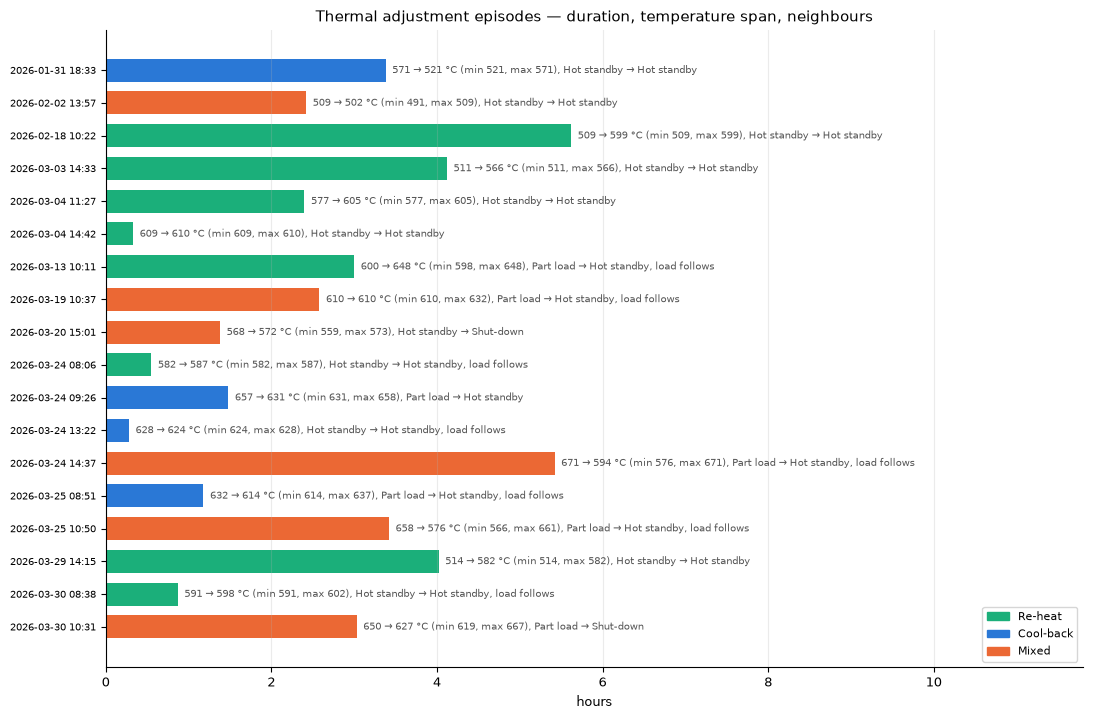

In [5]:
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(11, 0.32 * len(inv) + 1.5))
for y, (eid, r) in enumerate(inv.iterrows()):
    ax.barh(y, r.duration_h, color=KIND_COLORS[r.kind], height=0.7)
    tag = (
        f"{r.T_start_C:.0f} → {r.T_end_C:.0f} °C (min {r.T_min_C:.0f}, max "
        f"{r.T_max_C:.0f}), {r.before} → {r.after}"
    )
    tag += ", load follows" if r.load_follows else ""
    ax.text(r.duration_h + 0.08, y, tag, va="center", fontsize=7, color="#555")
ax.set_yticks(range(len(inv)))
ax.set_yticklabels([f"{r.date} {r.begin}" for _, r in inv.iterrows()], fontsize=7)
ax.invert_yaxis()
ax.set_xlabel("hours")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, inv.duration_h.max() * 2.1)

ax.legend(
    handles=[Patch(color=c, label=n) for n, c in KIND_COLORS.items()],
    loc="lower right",
    fontsize=8,
)
ax.set_title("Thermal adjustment episodes — duration, temperature span, neighbours")
fig.tight_layout()
fig.savefig(OUT / "episodes_overview.png", dpi=130)
plt.show()

## 3. What the hours contain, and the stage arrows

Minutes per operation and kind, then the stage before × after each episode. Every arrow must be one of the allowed
ones (before: Hot standby / Part load / Rated power; after: Hot standby / Shut-down).

In [6]:
opm = (
    s.groupby(["operation", "kind"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=list(KIND_COLORS), fill_value=0)
)
opm["hours"] = (opm.sum(axis=1) / 60).round(1)
opm = opm.sort_values("hours", ascending=False)
opm.to_csv(OUT / "operations.csv")
opm

kind,Re-heat,Cool-back,Mixed,hours
operation,,,,
Cool-back (no load),0,380,666,17.4
Re-heat to operating temperature,825,0,0,13.8
Re-heat (no load),429,0,284,11.9
Re-heat to hold,0,0,85,1.4
Temperature dip during hold,0,0,60,1.0


In [7]:
arrows = pd.crosstab(inv.before, inv.after, margins=True)
bad = inv[
    ~inv.before.isin(("Hot standby",) + LOAD)
    | ~inv.after.isin(("Hot standby", "Shut-down"))
]
print(f"episodes with an arrow that is not allowed: {len(bad)}")
# load minutes inside the stage (current ≥ 1 A): should be none, apart from the tail of
# a ramp-down
cur = s[s.I_string_A >= ops.I_LOAD]
print(
    f"minutes with I ≥ {ops.I_LOAD:.0f} A inside Thermal adjustment: {len(cur)} "
    f"({', '.join(sorted(set(cur.episode_id))) or 'none'}), max "
    f"{s.I_string_A.max():.1f} A"
)
arrows

episodes with an arrow that is not allowed: 0
minutes with I ≥ 1 A inside Thermal adjustment: 2 (20260304_1127_Thermal, 20260319_1037_Thermal), max 2.6 A


after,Hot standby,Shut-down,All
before,,,
Hot standby,10,1,11
Part load,6,1,7
All,16,2,18


## 4. Rate, against the 120 °C/h limit

### 4.1 Per episode

1-hour centred rate of the stack median (`dTdt`) and of the hottest and coldest thermocouple (`dTmax/dt`,
`dTmin/dt`), plus the fastest single thermocouple (largest |1-h change| of any valid thermocouple). The 1-hour window
reaches 30 min into the neighbouring block, so the first and last minutes of a cool-back right after a load stop
carry some of the load drop. The limit (120 °C/h) applies to the whole stack.

In [8]:
TCV = [c for c in ss.TC if c not in ss.TC_BROKEN]
t = d[TCV].where((d[TCV] > 0) & (d[TCV] < 1000))
t = t.where(t.sub(t.median(axis=1), axis=0).abs() <= ss.TC_OUTLIER_K).asfreq("1min")
tc_rate = (t.shift(-30) - t.shift(30)).reindex(d.index)
d["fastest_tc_C_per_h"] = tc_rate.abs().max(axis=1).where(tc_rate.notna().any(axis=1))
s = d[d.stage == STAGE]
rate = (
    s.groupby("episode_id")
    .agg(
        kind=("kind", "first"),
        median_rate=("dTdt_C_per_h", "median"),
        rise_max=("dTdt_C_per_h", "max"),
        fall_max=("dTdt_C_per_h", "min"),
        hottest_tc_max=("dTmaxdt_C_per_h", "max"),
        coldest_tc_min=("dTmindt_C_per_h", "min"),
        fastest_tc=("fastest_tc_C_per_h", "max"),
        rate20_max=("dTdt_20min_C_per_h", "max"),
        rate20_min=("dTdt_20min_C_per_h", "min"),
    )
    .loc[inv.index]
)
rate["minutes_over_limit_any_tc"] = s.groupby("episode_id").fastest_tc_C_per_h.apply(
    lambda x: int((x > LIMIT).sum())
)
rate.round(1).to_csv(OUT / "rates.csv")
up, dn = s[s.operation.isin(ops.REHEAT_OPS)], s[s.operation.isin(ops.COOL_BACK_OPS)]
print(
    f"re-heat minutes:   median {up.dTdt_C_per_h.median():+.0f} °C/h, p95 "
    f"{up.dTdt_C_per_h.quantile(0.95):+.0f}, "
    f"max {up.dTdt_C_per_h.max():+.0f} (stack median, 1 h)"
)
print(
    f"cool-back minutes: median {dn.dTdt_C_per_h.median():+.0f} °C/h, p5 "
    f"{dn.dTdt_C_per_h.quantile(0.05):+.0f}, "
    f"min {dn.dTdt_C_per_h.min():+.0f}"
)
print(
    f"fastest single thermocouple: p95 {s.fastest_tc_C_per_h.quantile(0.95):.0f} "
    f"°C/h, max {s.fastest_tc_C_per_h.max():.0f}; "
    f"{int((s.fastest_tc_C_per_h > LIMIT).sum())} minutes over {LIMIT:.0f} °C/h"
)
rate.round(1)

re-heat minutes:   median +12 °C/h, p95 +29, max +41 (stack median, 1 h)
cool-back minutes: median -15 °C/h, p5 -43, min -47
fastest single thermocouple: p95 56 °C/h, max 96; 0 minutes over 120 °C/h


,kind,median_rate,rise_max,fall_max,hottest_tc_max,coldest_tc_min,fastest_tc,rate20_max,rate20_min,minutes_over_limit_any_tc
episode_id,,,,,,,,,,
20260131_1833_Thermal,Cool-back,-14.4,-5.3,-22.7,-4.9,-51.4,51.7,-5.2,-24.5,0
20260202_1357_Thermal,Mixed,4.0,9.0,-17.8,9.4,-33.4,42.7,11.0,-24.5,0
20260218_1022_Thermal,Re-heat,15.5,25.0,4.1,53.1,6.4,53.1,26.1,4.9,0
20260303_1433_Thermal,Re-heat,13.1,20.7,4.5,44.6,7.3,51.4,22.3,5.2,0
20260304_1127_Thermal,Re-heat,8.0,17.8,5.5,19.9,3.3,26.6,27.1,3.5,0
20260304_1442_Thermal,Re-heat,4.4,4.7,4.1,4.3,0.8,6.7,6.2,5.1,0
20260313_1011_Thermal,Re-heat,19.0,31.8,8.7,49.7,-40.3,84.9,42.3,-9.5,0
20260319_1037_Thermal,Mixed,-6.9,41.1,-13.5,47.6,-15.1,49.1,76.7,-21.3,0
20260320_1501_Thermal,Mixed,1.1,13.2,-9.7,17.7,-64.5,90.8,24.0,-24.4,0


### 4.2 By operation

In [9]:
byop = s.groupby("operation").dTdt_C_per_h.describe(percentiles=[0.05, 0.5, 0.95])[
    ["count", "5%", "50%", "95%", "min", "max"]
]
byop.round(1)

,count,5%,50%,95%,min,max
operation,,,,,,
Cool-back (no load),1045.0,-43.3,-14.6,18.8,-46.7,54.7
Re-heat (no load),706.0,-7.4,10.3,30.1,-13.5,41.1
Re-heat to hold,85.0,0.8,6.3,8.3,-1.1,9.0
Re-heat to operating temperature,825.0,5.4,14.2,28.3,4.1,30.7
Temperature dip during hold,60.0,-17.7,-14.1,-3.4,-17.8,-1.7


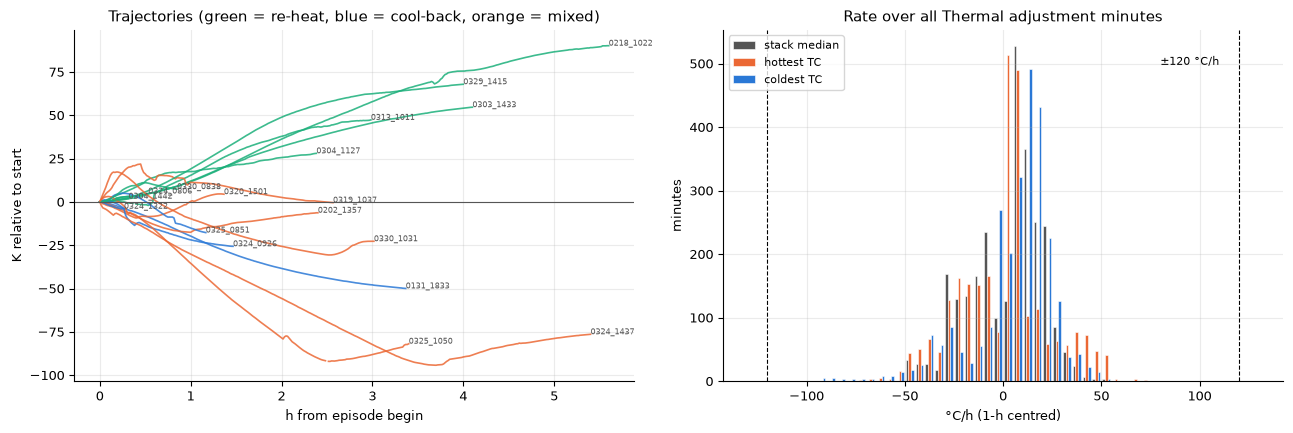

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
for eid, r in inv.iterrows():
    g = d[d.episode_id == eid]
    h = (g.index - g.index[0]).total_seconds() / 3600
    ax[0].plot(
        h, g.T_stack_C - r.T_start_C, color=KIND_COLORS[r.kind], lw=1.2, alpha=0.85
    )
    ax[0].text(
        h[-1],
        g.T_stack_C.dropna().iloc[-1] - r.T_start_C,
        eid[4:13],
        fontsize=6,
        color="#555",
    )
ax[0].axhline(0, color="#555", lw=0.8)
ax[0].set_xlabel("h from episode begin")
ax[0].set_ylabel("K relative to start")
ax[0].set_title("Trajectories (green = re-heat, blue = cool-back, orange = mixed)")
bins = np.arange(-130, 135, 5)
ax[1].hist(
    [s.dTdt_C_per_h.dropna(), s.dTmaxdt_C_per_h.dropna(), s.dTmindt_C_per_h.dropna()],
    bins=bins,
    color=["#555555", "#eb6834", "#2a78d6"],
    label=["stack median", "hottest TC", "coldest TC"],
    edgecolor="white",
    linewidth=0.4,
)
for v in (-LIMIT, LIMIT):
    ax[1].axvline(v, color="k", lw=0.8, ls="--")
ax[1].text(LIMIT - 40, ax[1].get_ylim()[1] * 0.9, "±120 °C/h", fontsize=8)
ax[1].set_xlabel("°C/h (1-h centred)")
ax[1].set_ylabel("minutes")
ax[1].legend(fontsize=8)
ax[1].set_title("Rate over all Thermal adjustment minutes")
fig.tight_layout()
fig.savefig(OUT / "rates.png", dpi=130)
plt.show()

### 4.3 The 2026-03-13 artefact (logger dropouts)

The library trace (`traces_1min.parquet`) still holds the dropout minutes. Its 1-h and 20-min rate and its minimum
for the 03-13 re-heat are compared with the cleaned trace from `stage_signals.load()`.

In [11]:
tr = pd.read_parquet(
    ss.LIB / "traces_1min.parquet", columns=["T_stack_C", "episode_id"]
)
raw = tr.T_stack_C.asfreq("1min")
tr["r20"] = ((raw.shift(-10) - raw.shift(10)) * 3).reindex(tr.index)
tr["r60"] = (raw.shift(-30) - raw.shift(30)).reindex(tr.index)
rows = []
for eid in [i for i in inv.index if i.startswith("20260313")]:
    a, b = tr[tr.episode_id == eid], d[d.episode_id == eid]
    rows.append(
        {
            "episode_id": eid,
            "trace": "library (raw)",
            "T_min_C": a.T_stack_C.min(),
            "rate60_max": a.r60.max(),
            "rate20_max": a.r20.max(),
            "rate20_min": a.r20.min(),
            "dropout_minutes": int((a.T_stack_C < 450).sum()),
        }
    )
    rows.append(
        {
            "episode_id": eid,
            "trace": "cleaned (stage_signals)",
            "T_min_C": b.T_stack_C.min(),
            "rate60_max": b.dTdt_C_per_h.max(),
            "rate20_max": b.dTdt_20min_C_per_h.max(),
            "rate20_min": b.dTdt_20min_C_per_h.min(),
            "dropout_minutes": int(b.logger_dropout.sum()),
        }
    )
art = pd.DataFrame(rows).set_index(["episode_id", "trace"])
print(
    "blanked minutes inside the stage:",
    ", ".join(s.index[s.logger_dropout].strftime("%m-%d %H:%M")),
)
art.round(1)

blanked minutes inside the stage: 03-13 10:15, 03-13 10:34


T_min_C  rate60_max  rate20_max  rate20_min  dropout_minutes
episode_id            trace                                                                                
20260313_1011_Thermal library (raw)              419.4       207.3       568.2        -9.5                1
                      cleaned (stage_signals)    598.4        31.8        42.3        -9.5                2

## 5. Heater (EAPH) and air

### 5.1 Per operation

Median levels per operation. The EAPH is controlled on its outlet temperature `TIRC_2_06` (= cathode inlet); its
target is `eaph_sp_C`. Flows in ln/min: air = FIRC 1.1.1 + 1.1.2, N₂ / H₂ = forming gas, NG = natural gas (FIRC 1.4),
POx air (FIRC 1.2). `share EAPH on` = minutes with P_EAPH > 0.2 kW.

In [12]:
HEAT = {
    "EAPH kW": "P_EAPH_kW",
    "EAPH output %": "eaph_out_pct",
    "EAPH outlet °C": "TIRC_2_06",
    "EAPH target °C": "eaph_sp_C",
    "outlet − stack K": "eaph_minus_stack_K",
    "air ln/min": "air_flow",
    "N2 ln/min": "N2",
    "H2 ln/min": "H2",
    "NG ln/min": "fuel",
    "POx air ln/min": "pox_air",
    "PIR_2_02": "P_air_in",
    "afterburner °C": "TIRC_5_09",
}
d["eaph_minus_stack_K"] = d.TIRC_2_06 - d.T_stack_C
s = d[d.stage == STAGE]
hs = d[(d.stage == "Hot standby") & (d.operation == "Temperature hold")]
lv = s.groupby("operation")[list(HEAT.values())].median()
lv.loc["Hot standby, Temperature hold (reference)"] = hs[list(HEAT.values())].median()
lv.columns = list(HEAT)
lv.insert(
    0,
    "share EAPH on",
    s.groupby("operation").P_EAPH_kW.apply(lambda x: (x > ops.EAPH_ON_W / 1000).mean()),
)
lv.loc["Hot standby, Temperature hold (reference)", "share EAPH on"] = (
    hs.P_EAPH_kW > ops.EAPH_ON_W / 1000
).mean()
lv.insert(0, "minutes", s.groupby("operation").size())
lv.loc["Hot standby, Temperature hold (reference)", "minutes"] = len(hs)
lv.round(2).to_csv(OUT / "heater_air_by_operation.csv")
lv.round(1).T

operation,Cool-back (no load),Re-heat (no load),Re-heat to hold,Re-heat to operating temperature,Temperature dip during hold,"Hot standby, Temperature hold (reference)"
minutes,1046.0,713.0,85.0,825.0,60.0,6275.0
share EAPH on,0.7,0.9,1.0,1.0,1.0,1.0
EAPH kW,4.7,13.8,10.8,19.2,4.8,13.4
EAPH output %,11.5,33.4,26.2,46.3,11.1,31.9
EAPH outlet °C,569.3,590.1,500.1,579.9,462.9,570.2
EAPH target °C,570.0,590.0,500.0,580.0,500.0,570.0
outlet − stack K,-49.4,-0.3,2.4,19.3,-35.1,-10.2
air ln/min,6000.2,6000.4,6000.0,6000.7,6000.0,6001.2
N2 ln/min,1199.9,1199.9,1200.0,1200.0,1199.9,1200.0
H2 ln/min,60.0,60.0,60.0,60.0,60.0,60.0


### 5.2 Per episode: what the controller was asked to do

`target_before → target_after` is the EAPH target in the 15 min before the episode and its last value inside it:
a re-heat or cool-back starts when the operator moves the target (or when a load stop takes the stack heat away).
`energy_kWh` is the heater energy over the episode; `kWh_per_K` only for net rises of ≥ 10 K.

In [13]:
rows = []
for eid, r in inv.iterrows():
    g = d[d.episode_id == eid]
    pre = d.loc[g.index[0] - pd.Timedelta("15min") : g.index[0] - pd.Timedelta("1min")]
    en = g.P_EAPH_kW.sum() / 60
    rows.append(
        {
            "episode_id": eid,
            "kind": r.kind,
            "dT_net_K": r.dT_net_K,
            "target_before_C": pre.eaph_sp_C.median(),
            "target_after_C": g.eaph_sp_C.dropna().iloc[-1],
            "ramp_K_per_h": g.eaph_sp_slew.median() * 3600,
            "EAPH_mean_kW": g.P_EAPH_kW.mean(),
            "EAPH_max_kW": g.P_EAPH_kW.max(),
            "energy_kWh": en,
            "kWh_per_K": en / r.dT_net_K if r.dT_net_K >= 10 else np.nan,
            "outlet_minus_stack_K": g.eaph_minus_stack_K.median(),
            "air_ln_min": g.air_flow.median(),
            "N2_minutes": int((g.N2 > 1).sum()),
            "NG_minutes": int((g.fuel > 5).sum()),
            "minutes": len(g),
        }
    )
heat = pd.DataFrame(rows).set_index("episode_id")
heat.round(1).to_csv(OUT / "heater_by_episode.csv")
heat.round(1)

,kind,dT_net_K,target_before_C,target_after_C,ramp_K_per_h,EAPH_mean_kW,EAPH_max_kW,energy_kWh,kWh_per_K,outlet_minus_stack_K,air_ln_min,N2_minutes,NG_minutes,minutes
episode_id,,,,,,,,,,,,,,
20260131_1833_Thermal,Cool-back,-49.9,500.0,500.0,60.1,6.9,9.2,23.2,NaN,-36.8,6000.0,203,0,203
20260202_1357_Thermal,Mixed,-6.3,0.0,500.0,60.1,8.3,11.1,20.0,NaN,-1.0,6000.0,145,0,145
20260218_1022_Thermal,Re-heat,90.1,500.0,600.0,60.1,21.5,29.2,120.9,1.3,25.9,6000.4,337,0,337
20260303_1433_Thermal,Re-heat,54.6,570.0,570.0,60.1,15.8,18.8,65.0,1.2,20.2,6000.0,247,0,247
20260304_1127_Thermal,Re-heat,28.0,570.0,600.0,60.1,11.2,12.0,26.8,1.0,0.5,5999.9,118,27,144
20260304_1442_Thermal,Re-heat,1.9,600.0,600.0,60.1,11.2,11.4,3.7,NaN,-9.7,5999.9,20,0,20
20260313_1011_Thermal,Re-heat,47.3,600.0,650.0,0.0,13.0,18.5,38.5,0.8,11.4,5999.8,149,0,180
20260319_1037_Thermal,Mixed,-0.4,580.0,580.0,60.1,4.1,10.1,10.7,NaN,-37.3,5999.8,135,9,155
20260320_1501_Thermal,Mixed,4.4,550.0,300.0,119.9,21.3,40.1,29.5,NaN,1.9,9999.8,83,0,83


In [14]:
print(
    "median EAPH kW by kind:", s.groupby("kind").P_EAPH_kW.median().round(1).to_dict()
)
print(
    "median air ln/min by kind:", s.groupby("kind").air_flow.median().round(0).to_dict()
)
print(
    f"reference Hot standby hold: EAPH {hs.P_EAPH_kW.median():.1f} kW, air "
    f"{hs.air_flow.median():.0f} ln/min"
)
re = heat[heat.kind == "Re-heat"]
print(
    f"re-heats: target raised by {(re.target_after_C - re.target_before_C).min():.0f}–"
    f"{(re.target_after_C - re.target_before_C).max():.0f} K; energy "
    f"{re.energy_kWh.min():.0f}–{re.energy_kWh.max():.0f} kWh, "
    f"{re.kWh_per_K.min():.2f}–{re.kWh_per_K.max():.2f} kWh/K"
)

median EAPH kW by kind: {'Cool-back': 6.6, 'Mixed': 4.6, 'Re-heat': 17.3}
median air ln/min by kind: {'Cool-back': 6000.0, 'Mixed': 6000.0, 'Re-heat': 6000.0}
reference Hot standby hold: EAPH 13.4 kW, air 6001 ln/min
re-heats: target raised by 0–100 K; energy 4–121 kWh, 0.81–1.34 kWh/K


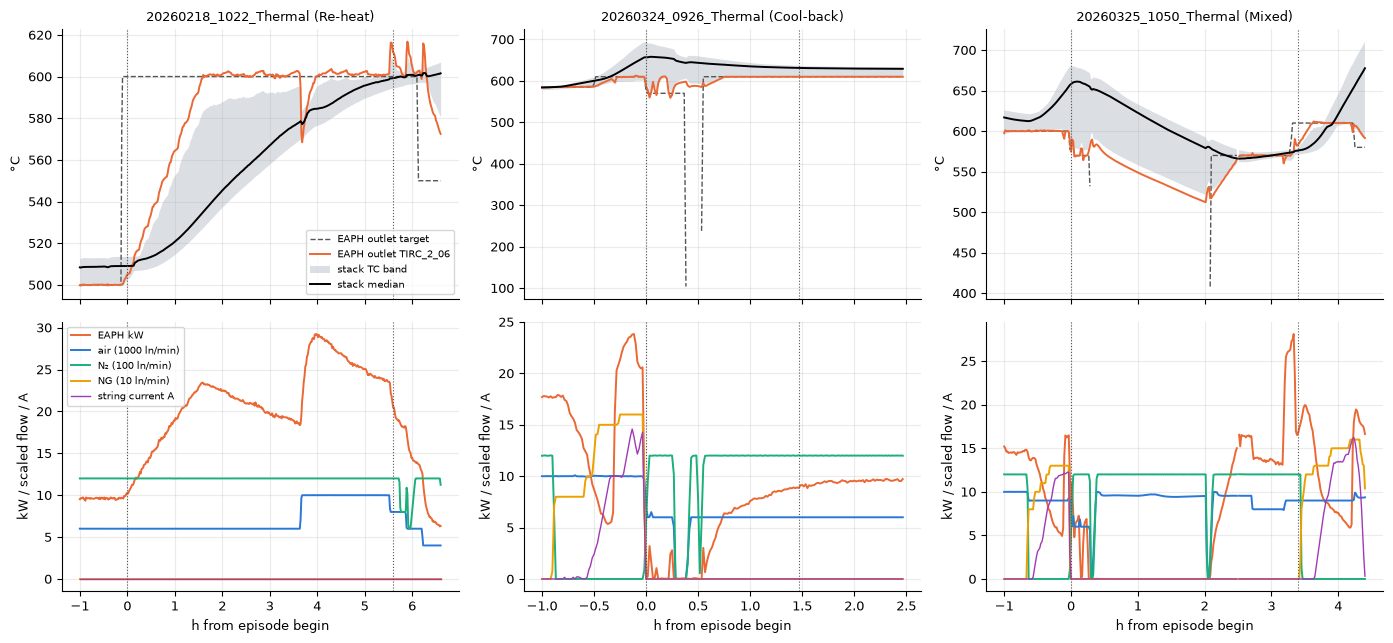

In [15]:
pick = [
    i
    for i in ("20260218_1022_Thermal", "20260324_0926_Thermal", "20260325_1050_Thermal")
    if i in inv.index
]
fig, axs = plt.subplots(2, len(pick), figsize=(14, 6.5), sharex="col")
for j, eid in enumerate(pick):
    g = d[d.episode_id == eid]
    w = d.loc[g.index[0] - pd.Timedelta("1h") : g.index[-1] + pd.Timedelta("1h")]
    h = (w.index - g.index[0]).total_seconds() / 3600
    a = axs[0, j]
    a.plot(
        h,
        w.eaph_sp_C.where(w.eaph_sp_C > 0),
        color="#555",
        lw=1,
        ls="--",
        label="EAPH outlet target",
    )
    a.plot(h, w.TIRC_2_06, color="#eb6834", label="EAPH outlet TIRC_2_06")
    a.fill_between(
        h,
        w.T_tc_min_C,
        w.T_tc_max_C,
        color="#9aa5b1",
        alpha=0.35,
        lw=0,
        label="stack TC band",
    )
    a.plot(h, w.T_stack_C, color="k", label="stack median")
    a.set_title(f"{eid} ({inv.at[eid, 'kind']})", fontsize=9)
    a.set_ylabel("°C")
    b = axs[1, j]
    b.plot(h, w.P_EAPH_kW, color="#eb6834", label="EAPH kW")
    b.plot(h, w.air_flow / 1000, color="#2a78d6", label="air (1000 ln/min)")
    b.plot(h, w.N2 / 100, color="#1baf7a", label="N₂ (100 ln/min)")
    b.plot(h, w.fuel / 10, color="#eda100", label="NG (10 ln/min)")
    b.plot(h, w.I_string_A, color="#a03ab5", lw=1, label="string current A")
    b.set_xlabel("h from episode begin")
    b.set_ylabel("kW / scaled flow / A")
    for x in axs[:, j]:
        x.axvline(0, color="#555", lw=0.8, ls=":")
        x.axvline(
            (g.index[-1] - g.index[0]).total_seconds() / 3600,
            color="#555",
            lw=0.8,
            ls=":",
        )
axs[0, 0].legend(fontsize=7)
axs[1, 0].legend(fontsize=7)
fig.tight_layout()
fig.savefig(OUT / "heater_examples.png", dpi=130)
plt.show()

Examples: a re-heat from the ~510 °C hold (02-18), a cool-back after a load run with an emergency stop (03-24 09:26)
and a mixed cool-back → re-heat after a trip (03-25 10:50). Dotted lines mark the episode begin and end; the lower
panels put the flows on one scaled axis only to show the order of switching.

## 6. Thermocouple spread and inlet-side lead

`spread` = hottest − coldest valid thermocouple; `inlet lead` = mean of `TIR_4_6_1…8` minus the mean of the others.
A re-heat drives the inlet side ahead (positive lead), a cool-back behind (negative). Reference: Hot standby
*Temperature hold*.

In [16]:
grad = s.groupby("operation").agg(
    minutes=("T_spread_K", "size"),
    spread_median_K=("T_spread_K", "median"),
    spread_p95_K=("T_spread_K", lambda x: x.quantile(0.95)),
    spread_max_K=("T_spread_K", "max"),
    inlet_lead_median_K=("T_inlet_lead_K", "median"),
    inlet_lead_min_K=("T_inlet_lead_K", "min"),
    inlet_lead_max_K=("T_inlet_lead_K", "max"),
)
grad.loc["Hot standby, Temperature hold (reference)"] = [
    len(hs),
    hs.T_spread_K.median(),
    hs.T_spread_K.quantile(0.95),
    hs.T_spread_K.max(),
    hs.T_inlet_lead_K.median(),
    hs.T_inlet_lead_K.min(),
    hs.T_inlet_lead_K.max(),
]
grad.round(1).to_csv(OUT / "thermal_gradient_by_operation.csv")
gep = (
    s.groupby("episode_id")
    .agg(
        kind=("kind", "first"),
        spread_median_K=("T_spread_K", "median"),
        spread_max_K=("T_spread_K", "max"),
        inlet_lead_median_K=("T_inlet_lead_K", "median"),
    )
    .loc[inv.index]
)
gep.round(1).to_csv(OUT / "thermal_gradient_by_episode.csv")
xx = s[["dTdt_C_per_h", "T_inlet_lead_K"]].dropna()
lead_slope, lead_c0 = np.polyfit(xx.dTdt_C_per_h, xx.T_inlet_lead_K, 1)
lead_r2 = np.corrcoef(xx.dTdt_C_per_h, xx.T_inlet_lead_K)[0, 1] ** 2
print(
    f"inlet lead ≈ {lead_c0:+.1f} K + {lead_slope:.2f} K per °C/h (R² {lead_r2:.2f}, "
    f"{len(xx):,} minutes)"
)
grad.round(1)

inlet lead ≈ -16.7 K + 1.19 K per °C/h (R² 0.49, 2,714 minutes)


,minutes,spread_median_K,spread_p95_K,spread_max_K,inlet_lead_median_K,inlet_lead_min_K,inlet_lead_max_K
operation,,,,,,,
Cool-back (no load),1046.0,51.8,92.2,151.5,-43.5,-106.3,15.8
Re-heat (no load),713.0,14.7,66.6,111.4,-1.4,-96.3,29.3
Re-heat to hold,85.0,8.1,9.1,9.3,-1.0,-4.9,2.3
Re-heat to operating temperature,825.0,21.7,49.9,56.2,14.3,-7.5,47.2
Temperature dip during hold,60.0,36.9,61.6,61.9,-32.1,-55.8,-3.6
"Hot standby, Temperature hold (reference)",6275.0,13.1,23.4,62.4,-9.7,-54.9,9.5


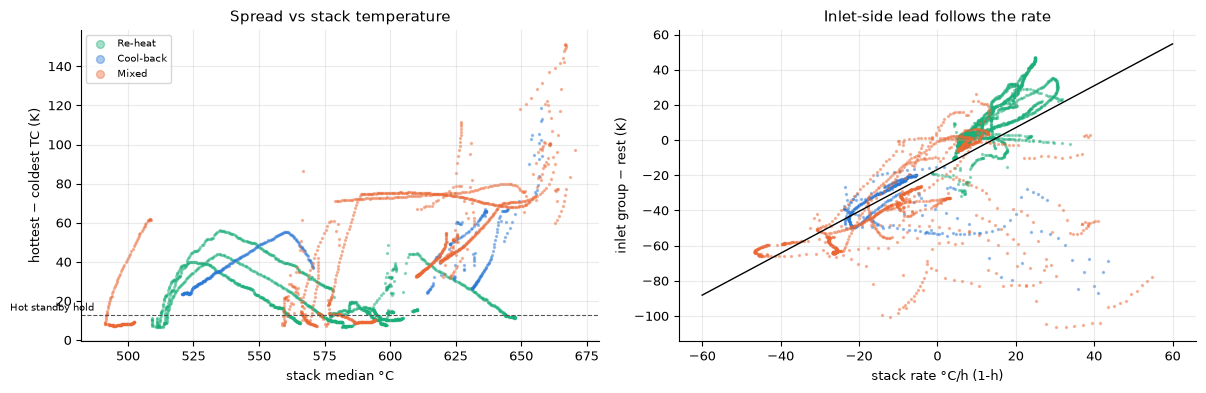

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for n, col in KIND_COLORS.items():
    z = s[s.kind == n]
    ax[0].scatter(z.T_stack_C, z.T_spread_K, s=2, color=col, alpha=0.4, label=n)
    ax[1].scatter(z.dTdt_C_per_h, z.T_inlet_lead_K, s=2, color=col, alpha=0.4, label=n)
ax[0].axhline(hs.T_spread_K.median(), color="#555", lw=0.8, ls="--")
ax[0].text(455, hs.T_spread_K.median() + 2, "Hot standby hold", fontsize=7)
ax[0].set_xlabel("stack median °C")
ax[0].set_ylabel("hottest − coldest TC (K)")
ax[0].set_title("Spread vs stack temperature")
xs = np.array([-60, 60])
ax[1].plot(xs, lead_c0 + lead_slope * xs, color="k", lw=1)
ax[1].set_xlabel("stack rate °C/h (1-h)")
ax[1].set_ylabel("inlet group − rest (K)")
ax[1].set_title("Inlet-side lead follows the rate")
ax[0].legend(fontsize=7, markerscale=4)
fig.tight_layout()
fig.savefig(OUT / "thermal_gradient.png", dpi=130)
plt.show()

## 7. What precedes load

Part load only follows Hot standby. When a Thermal adjustment runs up to the first load minute, the last 15 min
become Hot standby *Pre-load (ready for load)*. The table lists every Pre-load block in the library (one also sits at
the end of a long hold after the 03-12 start-up), and then, for every load start that follows a Thermal adjustment,
when the plant switched from forming gas (N₂ + H₂) to natural gas + POx air. Negative minutes = before the first load
minute.

In [18]:
pl_eps = e[e.operations.fillna("").str.contains(ops.PRE_LOAD, regex=False)]
rows = []
for _, r in pl_eps.iterrows():
    g = d[(d.episode_id == r.episode_id) & (d.operation == ops.PRE_LOAD)]
    rows.append(
        {
            "episode_id": r.episode_id,
            "before": r.prev_stage,
            "before_ops": r.prev_ops,
            "minutes": len(g),
            "T_start_C": g.T_stack_C.iloc[0],
            "T_end_C": g.T_stack_C.iloc[-1],
            "rate_in_block_C_per_h": (g.T_stack_C.iloc[-1] - g.T_stack_C.iloc[0])
            * 60
            / max(len(g) - 1, 1),
            "EAPH_kW": g.P_EAPH_kW.median(),
            "EAPH_target_C": g.eaph_sp_C.median(),
            "air_ln_min": g.air_flow.median(),
            "N2_ln_min_end": g.N2.iloc[-1],
            "NG_ln_min_end": g.fuel.iloc[-1],
            "POx_air_end": g.pox_air.iloc[-1],
            "I_max_A": g.I_string_A.max(),
        }
    )
pre = pd.DataFrame(rows).set_index("episode_id")
pre.round(1).to_csv(OUT / "preload_blocks.csv")
pre.round(1)

,before,before_ops,minutes,T_start_C,T_end_C,rate_in_block_C_per_h,EAPH_kW,EAPH_target_C,air_ln_min,N2_ln_min_end,NG_ln_min_end,POx_air_end,I_max_A
episode_id,,,,,,,,,,,,,
20260313_0113_Hot,Start-up,"Air flow start (purge, heater off) > Heat-up (...",19,581.6,594.4,42.7,9.3,600.0,6000.1,0.0,130.0,519.6,0.8
20260313_1311_Hot,Thermal adjustment,Re-heat (no load),15,647.9,653.6,24.4,14.4,650.0,5999.8,0.0,140.0,547.2,0.3
20260324_0839_Hot,Thermal adjustment,Re-heat (no load),15,587.2,597.7,44.8,14.5,585.0,9989.5,0.0,100.0,302.3,0.9
20260324_1339_Hot,Thermal adjustment,Cool-back (no load),15,624.4,623.4,-4.3,14.4,600.0,9620.1,0.0,80.0,360.2,1.0
20260325_1002_Hot,Thermal adjustment,Cool-back (no load),15,613.7,613.8,0.1,14.5,600.0,9996.2,0.0,80.0,348.8,0.2
20260325_1415_Hot,Thermal adjustment,Cool-back (no load) > Re-heat (no load),15,576.4,586.1,41.4,18.3,610.0,8999.2,0.0,130.0,493.6,0.3


In [19]:
def last_switch(on, t_load):
    """Minutes (relative to t_load) of the start of the last 'on' run before t_load,
    and of the last 'on' minute."""
    on = on[on.index < t_load]
    if not on.any():
        return np.nan, np.nan
    last_on = on[on].index[-1]
    off_before = on[on.index <= last_on]
    run_start = off_before[~off_before].index
    first = on[on.index > run_start[-1]].index[0] if len(run_start) else on.index[0]
    return (first - t_load).total_seconds() / 60, (
        last_on - t_load
    ).total_seconds() / 60 + 1


rows = []
for eid, r in inv[inv.load_follows].iterrows():
    i = order.index(eid)
    hsb, ld = e.iloc[i + 1], e.iloc[i + 2]
    t_load = ld.start
    w = d.loc[t_load - pd.Timedelta("6h") : t_load - pd.Timedelta("1min")]
    ng_on, _ = last_switch(w.fuel > 5, t_load)
    _, n2_off = last_switch(w.N2 > 1, t_load)
    pox_on, _ = last_switch(w.pox_air > 5, t_load)
    t_end = inv.at[eid, "min_to_load"]
    rows.append(
        {
            "episode_id": eid,
            "kind": r.kind,
            "hot_standby_between": hsb.operations,
            "hot_standby_min": round(hsb.duration_h * 60),
            "first_load": t_load.strftime("%m-%d %H:%M"),
            "TA_end_min": -t_end,
            "NG_on_min": ng_on,
            "POx_air_on_min": pox_on,
            "N2_off_min": n2_off,
            "NG_switch_in": ("Thermal adjustment" if ng_on < -t_end else "Hot standby")
            if pd.notna(ng_on)
            else "—",
            "T_at_load_C": d.T_stack_C.asof(t_load - pd.Timedelta("1min")),
            "rate_last_15min_C_per_h": w.T_stack_C.iloc[-15:].pipe(
                lambda v: (v.iloc[-1] - v.iloc[0]) * 60 / 14
            ),
        }
    )
sw = pd.DataFrame(rows).set_index("episode_id")
sw.round(1).to_csv(OUT / "switch_before_load.csv")
sw.round(1)

,kind,hot_standby_between,hot_standby_min,first_load,TA_end_min,NG_on_min,POx_air_on_min,N2_off_min,NG_switch_in,T_at_load_C,rate_last_15min_C_per_h
episode_id,,,,,,,,,,,
20260313_1011_Thermal,Re-heat,Pre-load (ready for load),15,03-13 13:26,-15.0,-8.0,-8.0,-7.0,Hot standby,653.6,24.4
20260319_1037_Thermal,Mixed,Temperature hold,139,03-19 15:31,-139.0,-7.0,-7.0,-6.0,Hot standby,606.5,6.2
20260324_0806_Thermal,Re-heat,Pre-load (ready for load),15,03-24 08:54,-15.0,-22.0,-22.0,-20.0,Thermal adjustment,597.7,44.8
20260324_1322_Thermal,Cool-back,Pre-load (ready for load),15,03-24 13:54,-15.0,-8.0,-8.0,-6.0,Hot standby,623.4,-4.3
20260324_1437_Thermal,Mixed,Temperature hold,736,03-25 08:18,-736.0,-5.0,-5.0,-4.0,Hot standby,602.1,4.8
20260325_0851_Thermal,Cool-back,Pre-load (ready for load),15,03-25 10:17,-15.0,-6.0,-6.0,-5.0,Hot standby,613.8,0.1
20260325_1050_Thermal,Mixed,Pre-load (ready for load),15,03-25 14:30,-15.0,-14.0,-14.0,-12.0,Hot standby,586.1,41.4
20260330_0838_Thermal,Re-heat,Temperature hold,38,03-30 10:08,-38.0,-15.0,-15.0,-13.0,Hot standby,604.2,25.9


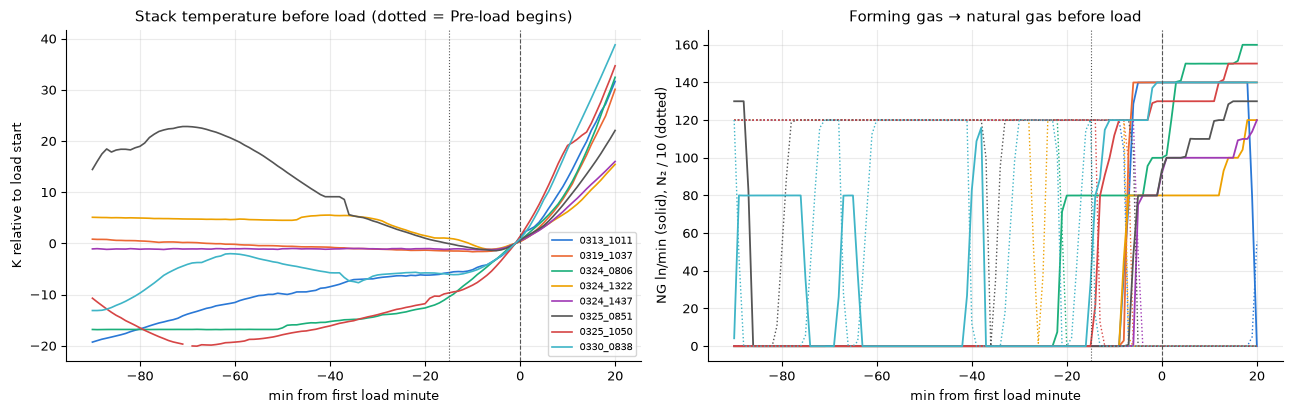

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
cols = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#a03ab5",
    "#555555",
    "#d64545",
    "#3fb5c7",
]
for (eid, r), col in zip(sw.iterrows(), cols):
    t_load = e.iloc[order.index(eid) + 2].start
    w = d.loc[t_load - pd.Timedelta("90min") : t_load + pd.Timedelta("20min")]
    m = (w.index - t_load).total_seconds() / 60
    ax[0].plot(
        m,
        w.T_stack_C - d.T_stack_C.asof(t_load - pd.Timedelta("1min")),
        color=col,
        lw=1.2,
        label=eid[4:13],
    )
    ax[1].plot(m, w.fuel, color=col, lw=1.3)
    ax[1].plot(m, w.N2 / 10, color=col, lw=1, ls=":")
for a in ax:
    a.axvline(0, color="#555", lw=0.8, ls="--")
    a.axvline(-ops.MIN_SEG_MIN, color="#555", lw=0.8, ls=":")
    a.set_xlabel("min from first load minute")
ax[0].set_ylabel("K relative to load start")
ax[0].set_title("Stack temperature before load (dotted = Pre-load begins)")
ax[0].legend(fontsize=7)
ax[1].set_ylabel("NG ln/min (solid), N₂ / 10 (dotted)")
ax[1].set_title("Forming gas → natural gas before load")
fig.tight_layout()
fig.savefig(OUT / "before_load.png", dpi=130)
plt.show()

## 8. Timings

Durations per kind and per operation block, and the clock time at which the episodes begin.

In [21]:
dur = inv.groupby("kind").duration_h.describe()[["count", "min", "50%", "max"]]
dur["total_h"] = inv.groupby("kind").duration_h.sum()
dur.loc["all"] = [
    len(inv),
    inv.duration_h.min(),
    inv.duration_h.median(),
    inv.duration_h.max(),
    inv.duration_h.sum(),
]
print(dur.round(2).to_string())
blk = (
    (s.operation != s.operation.shift()) | (s.episode_id != s.episode_id.shift())
).cumsum()
ob = s.groupby(blk).agg(
    operation=("operation", "first"),
    minutes=("operation", "size"),
    dT_K=("T_stack_C", lambda v: v.dropna().iloc[-1] - v.dropna().iloc[0]),
)
obd = ob.groupby("operation").agg(
    blocks=("minutes", "size"),
    min_minutes=("minutes", "min"),
    median_minutes=("minutes", "median"),
    max_minutes=("minutes", "max"),
    dT_min_K=("dT_K", "min"),
    dT_median_K=("dT_K", "median"),
    dT_max_K=("dT_K", "max"),
)
obd.round(1).to_csv(OUT / "operation_blocks.csv")
tm = inv[["date", "begin", "kind", "before", "after", "duration_h"]].assign(
    end=[e_idx.at[i, "end"].strftime("%H:%M") for i in inv.index]
)
tm.to_csv(OUT / "timings.csv")
obd.round(1)

           count   min   50%   max  total_h
kind                                       
Cool-back    4.0  0.28  1.33  3.38     6.32
Mixed        6.0  1.38  2.80  5.42    18.25
Re-heat      8.0  0.33  2.70  5.62    20.91
all         18.0  0.28  2.50  5.62    45.48


,blocks,min_minutes,median_minutes,max_minutes,dT_min_K,dT_median_K,dT_max_K
operation,,,,,,,
Cool-back (no load),9,17,89.0,225,-94.0,-25.6,-4.0
Re-heat (no load),10,20,48.0,180,1.9,8.5,47.3
Re-heat to hold,1,85,85.0,85,11.2,11.2,11.2
Re-heat to operating temperature,3,241,247.0,337,54.6,67.9,90.1
Temperature dip during hold,1,60,60.0,60,-17.5,-17.5,-17.5


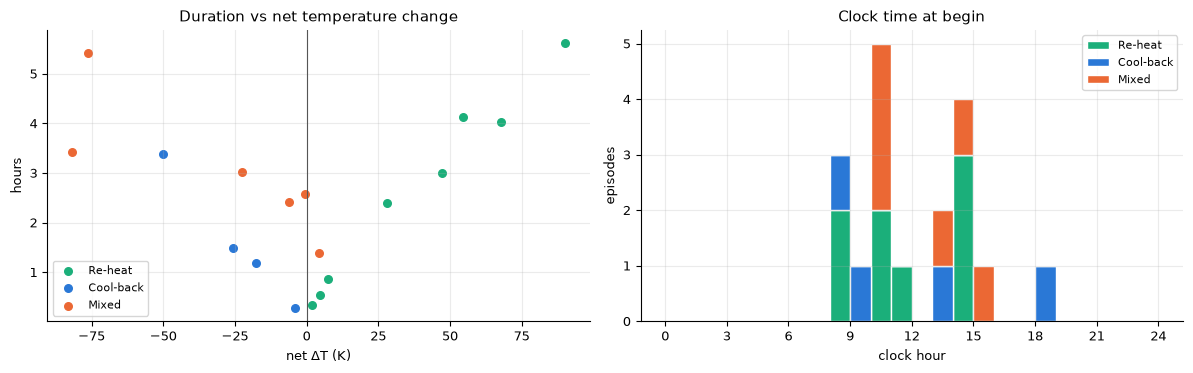

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for n, col in KIND_COLORS.items():
    z = inv[inv.kind == n]
    ax[0].scatter(z.dT_net_K, z.duration_h, color=col, label=n, s=30)
ax[0].axvline(0, color="#555", lw=0.8)
ax[0].set_xlabel("net ΔT (K)")
ax[0].set_ylabel("hours")
ax[0].set_title("Duration vs net temperature change")
ax[0].legend(fontsize=8)
hrs = pd.to_datetime(inv.begin, format="%H:%M")
ax[1].hist(
    [
        hrs[inv.kind == n].dt.hour + hrs[inv.kind == n].dt.minute / 60
        for n in KIND_COLORS
    ],
    bins=np.arange(0, 25, 1),
    color=list(KIND_COLORS.values()),
    label=list(KIND_COLORS),
    stacked=True,
    edgecolor="white",
)
ax[1].set_xticks(range(0, 25, 3))
ax[1].set_xlabel("clock hour")
ax[1].set_ylabel("episodes")
ax[1].set_title("Clock time at begin")
ax[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "timings.png", dpi=130)
plt.show()

## 9. Signal levels for synthetic data

Median and quartiles per operation of the signals a generator needs, plus the noise σ (robust standard deviation of
the 1-min first difference / √2, as in the other stage notebooks), separately for rising and falling operations.

In [23]:
LEV = {
    "stack rate °C/h": "dTdt_C_per_h",
    "EAPH kW": "P_EAPH_kW",
    "EAPH outlet °C": "TIRC_2_06",
    "EAPH target °C": "eaph_sp_C",
    "air ln/min": "air_flow",
    "N2 ln/min": "N2",
    "H2 ln/min": "H2",
    "NG ln/min": "fuel",
    "PIR_2_02": "P_air_in",
    "TC spread K": "T_spread_K",
    "inlet lead K": "T_inlet_lead_K",
    "afterburner TIRC_5_09 °C": "TIRC_5_09",
    "reformer in TIRC_3_07 °C": "TIRC_3_07",
    "roof exhaust TIR_7_05 °C": "TIR_7_05",
}
q = s.groupby("operation")[list(LEV.values())].quantile([0.25, 0.5, 0.75]).unstack()
lev = pd.DataFrame(
    {
        k: q[c].apply(lambda r: f"{r[0.5]:.1f} ({r[0.25]:.0f}…{r[0.75]:.0f})", axis=1)
        for k, c in LEV.items()
    }
)
lev.insert(0, "minutes", s.groupby("operation").size())
s.groupby("operation")[list(LEV.values())].median().rename(
    columns={v: k for k, v in LEV.items()}
).round(2).to_csv(OUT / "levels_by_operation.csv")
lev.T

operation,Cool-back (no load),Re-heat (no load),Re-heat to hold,Re-heat to operating temperature,Temperature dip during hold
minutes,1046,713,85,825,60
stack rate °C/h,-14.6 (-26…-7),10.3 (6…17),6.3 (6…7),14.2 (9…21),-14.1 (-17…-10)
EAPH kW,4.7 (0…7),13.8 (10…18),10.8 (11…11),19.2 (17…23),4.8 (2…7)
EAPH outlet °C,569.3 (524…580),590.1 (580…600),500.1 (500…500),579.9 (570…600),462.9 (448…477)
EAPH target °C,570.0 (500…580),590.0 (580…600),500.0 (500…500),580.0 (570…600),500.0 (500…500)
air ln/min,6000.2 (6000…7991),6000.4 (6000…9997),6000.0 (6000…6000),6000.7 (6000…9000),6000.0 (6000…6000)
N2 ln/min,1199.9 (1199…1200),1199.9 (1199…1200),1200.0 (1200…1200),1200.0 (1200…1200),1199.9 (1199…1200)
H2 ln/min,60.0 (60…60),60.0 (60…60),60.0 (60…60),60.0 (60…60),60.0 (60…60)
NG ln/min,0.0 (0…0),0.0 (0…0),0.0 (0…0),0.0 (0…0),0.0 (0…0)
PIR_2_02,14.2 (13…20),14.3 (14…26),12.3 (12…12),13.0 (13…22),12.3 (12…12)


In [24]:
noise = pd.DataFrame(
    {
        "re-heat": {k: ss.robust_sigma(up[c]) for k, c in LEV.items()},
        "cool-back": {k: ss.robust_sigma(dn[c]) for k, c in LEV.items()},
    }
)
noise.round(3).to_csv(OUT / "noise_sigma.csv")
noise.round(3)

,re-heat,cool-back
stack rate °C/h,0.170,0.210
EAPH kW,0.105,0.062
EAPH outlet °C,0.243,0.466
EAPH target °C,0.000,0.000
air ln/min,0.751,0.840
N2 ln/min,0.165,0.486
H2 ln/min,0.000,0.000
NG ln/min,0.000,0.000
PIR_2_02,0.025,0.023
TC spread K,0.169,0.242


## 10. Summary

In [25]:
rh_ops = inv[inv.kind == "Re-heat"]
summary = pd.Series(
    {
        "Thermal adjustment minutes": (
            f"{len(s):,} ({len(s) / 60:.1f} h, {len(s) / len(d):.1%} of logged time)"
        ),
        "Episodes": ", ".join(f"{n} {k}" for k, n in inv.kind.value_counts().items()),
        "Arrows in": ", ".join(
            f"{k} {n}" for k, n in inv.before.value_counts().items()
        ),
        "Arrows out": ", ".join(
            f"{k} {n}" for k, n in inv.after.value_counts().items()
        ),
        "Duration": (
            f"{inv.duration_h.min():.2f}–{inv.duration_h.max():.2f} h (median "
            f"{inv.duration_h.median():.1f} h)"
        ),
        "Net ΔT": (
            f"{inv.dT_net_K.min():+.0f} to {inv.dT_net_K.max():+.0f} K; largest swing "
            f"{inv.swing_K.max():.0f} K"
        ),
        "Re-heat rate, median / p95 (stack, 1 h)": (
            f"{up.dTdt_C_per_h.median():+.0f} / "
            f"{up.dTdt_C_per_h.quantile(0.95):+.0f} °C/h"
        ),
        "Cool-back rate, median / p5 (stack, 1 h)": (
            f"{dn.dTdt_C_per_h.median():+.0f} / "
            f"{dn.dTdt_C_per_h.quantile(0.05):+.0f} °C/h"
        ),
        "Fastest single TC, max": (
            f"{s.fastest_tc_C_per_h.max():.0f} °C/h "
            f"({int((s.fastest_tc_C_per_h > LIMIT).sum())} min > 120)"
        ),
        "EAPH median kW, re-heat / cool-back / HS hold": (
            f"{up.P_EAPH_kW.median():.1f} / {dn.P_EAPH_kW.median():.1f} / "
            f"{hs.P_EAPH_kW.median():.1f}"
        ),
        "TC spread median, re-heat / cool-back / HS hold": (
            f"{up.T_spread_K.median():.0f} / {dn.T_spread_K.median():.0f} / "
            f"{hs.T_spread_K.median():.0f} K"
        ),
        "Inlet lead vs rate": (
            f"{lead_c0:+.1f} K + {lead_slope:.2f} K per °C/h (R² {lead_r2:.2f})"
        ),
        "Load follows": (
            f"{inv.load_follows.sum()} of {len(inv)} ({inv.via_preload.sum()} via "
            "the 15-min Pre-load)"
        ),
        "NG on before first load minute": (
            f"{-sw.NG_on_min.max():.0f}–{-sw.NG_on_min.min():.0f} min"
        ),
        "N2 off before first load minute": (
            f"{-sw.N2_off_min.max():.0f}–{-sw.N2_off_min.min():.0f} min"
        ),
    },
    name="value",
)
summary.to_csv(OUT / "summary.csv")
summary.to_frame()

,value
Thermal adjustment minutes,"2,729 (45.5 h, 5.0% of logged time)"
Episodes,"8 Re-heat, 6 Mixed, 4 Cool-back"
Arrows in,"Hot standby 11, Part load 7"
Arrows out,"Hot standby 16, Shut-down 2"
Duration,0.28–5.62 h (median 2.5 h)
Net ΔT,-82 to +90 K; largest swing 95 K
"Re-heat rate, median / p95 (stack, 1 h)",+12 / +29 °C/h
"Cool-back rate, median / p5 (stack, 1 h)",-15 / -43 °C/h
"Fastest single TC, max",96 °C/h (0 min > 120)
"EAPH median kW, re-heat / cool-back / HS hold",16.7 / 4.7 / 13.4


### Findings

**How much and what kind (§1–3)**
- Thermal adjustment covers **45.5 h (5.0 %)** of the 39 logged days in **18 episodes**: 8 re-heats (20.9 h),
  4 cool-backs (6.3 h) and 6 mixed (18.2 h). Durations 0.28–5.62 h, median 2.5 h.
- All arrows are allowed: in from Hot standby (11) or Part load (7); out to Hot standby (16) or Shut-down (2:
  03-20 15:01, 03-30 10:31). Two minutes carry a little current (max 2.6 A, the tail of a load stop on 03-19 and
  03-04).
- Net ΔT −82 to +90 K; the largest swings (94–95 K) are the two mixed episodes after an emergency stop / trip
  (03-24 14:37 and 03-25 10:50: 670 → 576 °C and 658 → 566 °C, then a re-heat). 4 episodes contain a safety event.
- The three *Re-heat to operating temperature* blocks take the stack from the ~510 °C hold to 566–599 °C in
  4.0–5.6 h (+55 to +90 K). 5 of the 7 episodes that follow a load run begin as a cool-back; 03-13 and 03-19 begin
  as a re-heat.

**Rate against the 120 °C/h limit (§4)**
- Re-heat minutes: median **+12 °C/h**, p95 +29, max +41 °C/h (stack median, 1 h). Cool-back minutes: median
  **−15 °C/h**, p5 −43, min −47 °C/h. *Re-heat to operating temperature* runs at a median 14 °C/h.
- The fastest single thermocouple reaches **96 °C/h** (03-30 10:31, right after a load stop); **no minute is above
  120 °C/h**. Thermal adjustment is well inside the limit.
- **2026-03-13 artefact:** the library trace still holds the 10:34 dropout minute (419 °C). It gives a 1-h re-heat rate
  of **207 °C/h** (568 °C/h on a 20-min window) and a minimum of 419 °C. With the dropout minutes blanked
  (10:15, 10:34) the re-heat runs at **≤ 32 °C/h** (1 h; 42 °C/h on 20 min) and never falls below 598 °C. The third
  dropout (03-23 08:43) is not inside this stage.

**Heater and air (§5)**
- Re-heat: EAPH median **16.7 kW** over all re-heat minutes (19.2 kW and 46 % output on *Re-heat to operating
  temperature*, with the outlet 19 K above the stack; 13.8 kW on *Re-heat (no load)*). Hot standby hold: 13.4 kW. Cool-back: **4.7 kW** (heater off 30 % of the minutes), the outlet ~49 K
  below the stack.
- The re-heats use 4–121 kWh, **0.8–1.3 kWh per K** of net rise. The EAPH target is raised by 0–100 K at or before
  the start (e.g. 500 → 600 °C on 02-18); on 03-03 and 03-29 the target was already 570–580 °C during the hold.
- Air stays at **6 000 ln/min** (median of every kind); some March episodes run at 9 000–10 000 ln/min. Forming gas
  (N₂ 1 200 + H₂ 60 ln/min) stays on in every operation; natural gas is 0 in the median, with NG minutes only in
  5 episodes (just before or after a load run or load attempt).

**Thermocouple spread (§6)**
- Spread median: **52 K** on cool-back (p95 92, max 152 K), 8–22 K on re-heat, against 13 K in the Hot standby
  hold. The inlet-side group lags by −44 K on cool-back and leads by +14 K on *Re-heat to operating temperature*.
- Inlet lead ≈ −16.7 K + **1.19 K per °C/h** (R² 0.49), the same 1.2 K per °C/h slope as in the start-up and
  shut-down notebooks.

**What precedes load (§7)**
- Load follows **8 of 18** episodes; **5 directly**, through the 15-min Hot standby *Pre-load* (the other 3 after a
  Hot standby hold of 38 min, 2.3 h and 12.3 h).
- In the Pre-load the stack is often still rising (**+24 to +45 °C/h** on 4 of 6 blocks), so "Hot standby"
  here is a label for the last 15 min, not a flat temperature.
- Natural gas + POx air come on **5–22 min** before the first load minute and N₂ goes off **4–20 min** before it,
  1–2 min after the NG. Only on 03-24 08:06 does the switch fall inside the Thermal adjustment (22 min before load);
  in the other 7 it falls inside the Hot standby block.

**Timings (§8)**
- Cool-back blocks 17–225 min (median 89, −4 to −94 K); re-heat blocks 20–180 min (median 48, +2 to +47 K);
  *Re-heat to operating temperature* 241–337 min. Episodes begin between 08:06 and 18:33, mostly in the morning
  or early afternoon.

### For the synthetic-data generator
| Parameter | Re-heat | Cool-back |
|---|---|---|
| Stack rate (1 h, median, IQR) | +10…+14 °C/h (6…21) | −15 °C/h (−26…−7) |
| Size | +2 to +90 K, 0.3–5.6 h | −4 to −94 K, 17–225 min per block |
| EAPH | 11–19 kW, outlet ≈ target (500–650 °C) | ~5 kW, often off; outlet ~50 K below stack |
| Air / forming gas | 6 000 ln/min (9 000–10 000 in late March); N₂ 1 200 + H₂ 60 | same |
| TC spread / inlet lead | 8–22 K / ≈ −17 K + 1.2 K per °C/h | 52 K / −44 K |
| Noise σ per min (stack rate, EAPH kW, air) | 0.17, 0.11, 0.75 | 0.21, 0.06, 0.84 |
| Before load | last 15 min = Hot standby Pre-load; NG + POx air on 5–22 min, N₂ off 4–20 min before current | |

### Open points
1. **Pre-load label**: the 15-min Pre-load is Hot standby although the stack can still rise at ~45 °C/h. Keep, or
   let Pre-load be a Thermal adjustment operation when |dT/dt| ≥ 5 °C/h?
2. **Library T_min for 03-13**: `episodes.csv` still lists T_min 419 °C and T_start NaN from the dropout minutes.
   Blank dropouts in `operating_states.py` too, so the library carries the cleaned values?